In [5]:
from datasets import load_dataset

dataset = load_dataset("FahdSeddik/AGS-Corpus")
print(dataset)
import pandas as pd

df = dataset["train"].to_pandas()
print(df.head())

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'summary'],
        num_rows: 141467
    })
})
   id                                               text  \
0   0  يمكن تصور السلوكيات المُهَدِدة باعتبارها ثمرة ...   
1   1  يقدِّر المؤرِّخون مجموع عدد الرقيق خلال الفترة...   
2   2  الرياض قامت صباح أمس السبت بجولة في سوق السبت ...   
3   3  كان السميلودون آخر أجناس السنوريَّات سيفيَّة ا...   
4   4  وقال سموه في كلمة له بمناسبة اليوم الوطني ان ك...   

                                             summary  
0  السلوكيات المهددة يمكن أن تكون نتيجة عدم القدر...  
1  يُقدِّر عدد الرقيق خلال الفترة الممتدة من 650 ...  
2  قامت الرياض صباح أمس السبت بجولة في سوق السبت ...  
3  السميلودون هو آخر أجناس السنوريات سيفية الأنيا...  
4  لم يكن اليوم الوطني يعتبر تحقيقًا لولا مسيرة ا...  


In [6]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42)

val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

print(len(train_df), len(val_df), len(test_df))
train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)
test_df.to_csv("test.csv", index=False)

113173 14147 14147


In [7]:
!pip install transformers datasets sentencepiece accelerate evaluate rouge_score

In [8]:
from sklearn.model_selection import train_test_split

# 🔥 Split: 80% train, 20% temp
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42)

# 🔥 Split temp → 10% validation + 10% test
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

# 📊 Print sizes
print("📌 Dataset Splits:")
print(f"Train size      : {len(train_df)}")
print(f"Validation size : {len(val_df)}")
print(f"Test size       : {len(test_df)}")

print("\n📊 Total samples:", len(df))

# 💾 Save as CSV files
train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)
test_df.to_csv("test.csv", index=False)

print("\n✅ Files saved successfully:")
print("train.csv")
print("validation.csv")
print("test.csv")

📌 Dataset Splits:
Train size      : 113173
Validation size : 14147
Test size       : 14147

📊 Total samples: 141467

✅ Files saved successfully:
train.csv
validation.csv
test.csv


In [9]:
print("📊 Dataset Type:")
print(type(df))

print("\n📊 Dataset Shape:")
print(df.shape)

print("\n📊 Columns:")
print(df.columns)

print("\n📄 Sample row:")
print(df.iloc[0])
# 🔍 نحاول نعرف لو فيه domain column
possible_cols = ["domain", "category", "label", "type"]

for col in possible_cols:
    if col in df.columns:
        print(f"\n📌 Found domain column: {col}")
        print(df[col].value_counts())
        break
else:
    print("⚠️ No explicit domain column found in dataset")

📊 Dataset Type:
<class 'pandas.core.frame.DataFrame'>

📊 Dataset Shape:
(141467, 3)

📊 Columns:
Index(['id', 'text', 'summary'], dtype='object')

📄 Sample row:
id                                                         0
text       يمكن تصور السلوكيات المُهَدِدة باعتبارها ثمرة ...
summary    السلوكيات المهددة يمكن أن تكون نتيجة عدم القدر...
Name: 0, dtype: object
⚠️ No explicit domain column found in dataset


In [10]:
print("📌 Missing values per column:")
print(df.isnull().sum())

📌 Missing values per column:
id         0
text       0
summary    0
dtype: int64


In [11]:
text_col = "text" if "text" in df.columns else df.columns[0]
summary_col = "summary" if "summary" in df.columns else df.columns[1]

print("📌 Empty texts:")
print("Text empty:", (df[text_col] == "").sum())
print("Summary empty:", (df[summary_col] == "").sum())
df["text_len"] = df[text_col].astype(str).apply(len)
df["summary_len"] = df[summary_col].astype(str).apply(len)

print("📊 Text length stats:")
print(df["text_len"].describe())

print("\n📊 Summary length stats:")
print(df["summary_len"].describe())

📌 Empty texts:
Text empty: 0
Summary empty: 0
📊 Text length stats:
count    141467.000000
mean       1090.529445
std         484.976112
min          75.000000
25%         714.000000
50%        1063.000000
75%        1432.000000
max        3761.000000
Name: text_len, dtype: float64

📊 Summary length stats:
count    141467.000000
mean        350.555105
std         133.208768
min          45.000000
25%         252.000000
50%         351.000000
75%         446.000000
max        1068.000000
Name: summary_len, dtype: float64


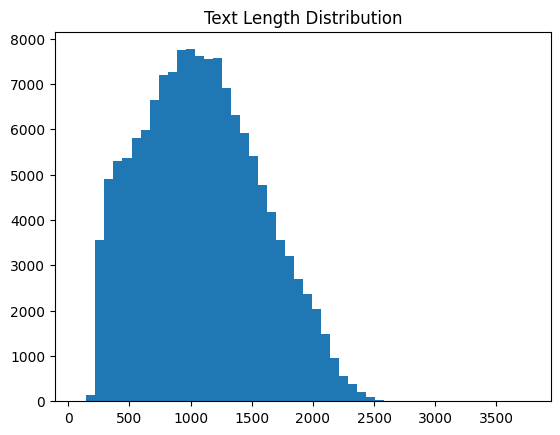

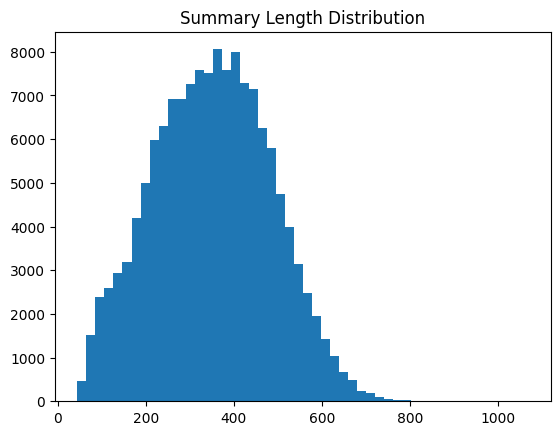

In [12]:
import matplotlib.pyplot as plt

plt.hist(df["text_len"], bins=50)
plt.title("Text Length Distribution")
plt.show()

plt.hist(df["summary_len"], bins=50)
plt.title("Summary Length Distribution")
plt.show()

In [13]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/mt5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

In [14]:
!pip install evaluate rouge_score -q

In [ ]:
# =========================
# INSTALL REQUIRED LIBRARIES
# =========================
!pip install evaluate rouge_score -q

# =========================
# IMPORTS
# =========================
from datasets import load_dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

from sklearn.model_selection import train_test_split

import evaluate
import torch
from tqdm import tqdm

# =========================
# 1) LOAD DATASET
# =========================
raw_dataset = load_dataset("FahdSeddik/AGS-Corpus")

df = raw_dataset["train"].to_pandas()

# =========================
# 2) SPLIT DATA
# =========================
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42
)

dataset = DatasetDict({
    "train": raw_dataset["train"].from_pandas(train_df),
    "validation": raw_dataset["train"].from_pandas(val_df),
    "test": raw_dataset["train"].from_pandas(test_df)
})

# =========================
# 3) LOAD MODEL
# =========================
# Better model for summarization
model_name = "csebuetnlp/mT5_multilingual_XLSum"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSeq2SeqLM.from_pretrained(
    model_name,
    tie_word_embeddings=False
)

# =========================
# 4) DEVICE
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

model.to(device)

# =========================
# 5) LOAD ROUGE
# =========================
rouge = evaluate.load("rouge")

# =========================
# 6) SUMMARIZATION FUNCTION
# =========================
def summarize(text):

    input_text = "summarize: " + str(text)

    inputs = tokenizer(
        input_text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_length=128,
            min_length=20,
            num_beams=6,
            no_repeat_ngram_size=3,
            repetition_penalty=2.5,
            length_penalty=1.0,
            early_stopping=True
        )

    summary = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return summary

# =========================
# 7) EVALUATION FUNCTION
# =========================
def evaluate_dataset(split_name):

    predictions = []
    references = []

    data = dataset[split_name]

    print(f"\n========== Evaluating {split_name.upper()} ==========\n")

    for sample in tqdm(data):

        text = sample["text"]
        reference = sample["summary"]

        prediction = summarize(text)

        predictions.append(prediction)
        references.append(reference)

    # =========================
    # CALCULATE ROUGE
    # =========================
    scores = rouge.compute(
        predictions=predictions,
        references=references,
        use_stemmer=True
    )

    print(f"\n========== {split_name.upper()} RESULTS ==========")

    print(f"ROUGE-1 : {scores['rouge1']:.4f}")
    print(f"ROUGE-2 : {scores['rouge2']:.4f}")
    print(f"ROUGE-L : {scores['rougeL']:.4f}")

    # =========================
    # PRINT SAMPLE RESULTS
    # =========================
    print("\n========== SAMPLE OUTPUT ==========\n")

    for i in range(2):

        print(f"\n--- Example {i+1} ---")

        print("\nTEXT:\n")
        print(data[i]["text"][:1000])

        print("\nREFERENCE SUMMARY:\n")
        print(data[i]["summary"])

        print("\nGENERATED SUMMARY:\n")
        print(predictions[i])

        print("\n" + "="*80)

# =========================
# 8) VALIDATION EVALUATION
# =========================
evaluate_dataset("validation")

# =========================
# 9) TEST EVALUATION
# =========================
evaluate_dataset("test")